# Lab 1: Sentiment Analysis Using Traditional Machine Learning

In [1]:
import re
import string
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

nltk.download("stopwords", quiet=True)

True

## 1. Download and load the dataset

In [2]:
!wget -q -O sentiment.zip "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
!unzip -q -o sentiment.zip

files = ["amazon_cells_labelled.txt", "imdb_labelled.txt", "yelp_labelled.txt"]
df = pd.concat(
    [pd.read_csv(f"sentiment labelled sentences/{f}", sep="\t", header=None,
                 names=["text", "label"], quoting=3) for f in files],
    ignore_index=True,
)
print(df.shape)
print(df["label"].value_counts())
df.head()

(3000, 2)
label
0    1500
1    1500
Name: count, dtype: int64


,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


## 2. Text preprocessing

In [3]:
def clean_text(text):
    text = text.lower()
    text = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head(10)

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


Cleaning made all the text lowercase and removed punctuation and extra spaces, so words like *Great!* and *great* are now treated as the same word.

## 3. Explore the text data

In [4]:
print("Positive examples:")
for t in df[df["label"] == 1]["text"].head(5):
    print(" ", t)

print("\nNegative examples:")
for t in df[df["label"] == 0]["text"].head(5):
    print(" ", t)

Positive examples:
  Good case, Excellent value.
  Great for the jawbone.
  The mic is great.
  If you are Razr owner...you must have this!
  And the sound quality is great.

Negative examples:
  So there is no way for me to plug it in here in the US unless I go by a converter.
  Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
  I have to jiggle the plug to get it to line up right to get decent volume.
  If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.
  Needless to say, I wasted my money.


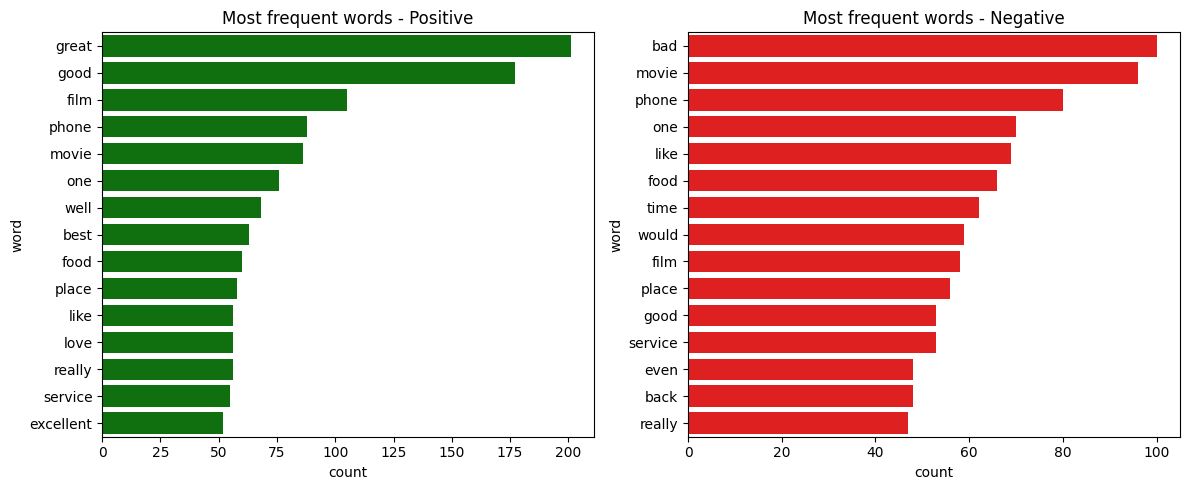

In [5]:
stop_words = set(stopwords.words("english"))

def top_words(texts, n=15):
    words = [w for t in texts for w in t.split() if w not in stop_words]
    return pd.DataFrame(Counter(words).most_common(n), columns=["word", "count"])

pos_words = top_words(df[df["label"] == 1]["clean_text"])
neg_words = top_words(df[df["label"] == 0]["clean_text"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=pos_words, x="count", y="word", ax=axes[0], color="green")
axes[0].set_title("Most frequent words - Positive")
sns.barplot(data=neg_words, x="count", y="word", ax=axes[1], color="red")
axes[1].set_title("Most frequent words - Negative")
plt.tight_layout()
plt.show()

Words like *great* and *good* appear a lot in positive reviews, while *bad* is the top word in negative ones. Topic words such as *phone*, *food* and *movie* appear in both. *Good* also appears in negative reviews, probably from phrases like "not good", because *not* is removed as a stop word.

## 4. Split the dataset

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 2400  Test: 600


## 5. Bag-of-Words representation

In [7]:
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Vocabulary size: 4560


## 6. Train ML models

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": LinearSVC(),
}
for model in models.values():
    model.fit(X_train_bow, y_train)

## 7. Evaluate the models

In [9]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test_bow)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.823,0.809,0.847,0.827
1,SVM,0.813,0.790,0.853,0.821


Logistic Regression did slightly better (accuracy 0.823, F1 0.827) than SVM (accuracy 0.813, F1 0.821), so simple word counts already capture most of the sentiment. Recall is a bit higher than precision for both, which means the models lean slightly towards predicting *positive*.

## 8. Test with new sentences

In [10]:
new_sentences = [
    "This phone is amazing and the battery lasts all day",
    "Worst service I have ever had",
    "The movie was boring and too long",
    "Great food and friendly staff",
]
X_new = vectorizer.transform([clean_text(s) for s in new_sentences])

predictions = pd.DataFrame({"Sentence": new_sentences})
for name, model in models.items():
    predictions[name] = ["Positive" if p == 1 else "Negative" for p in model.predict(X_new)]
predictions

,Sentence,Logistic Regression,SVM
0,This phone is amazing and the battery lasts al...,Positive,Positive
1,Worst service I have ever had,Negative,Negative
2,The movie was boring and too long,Negative,Negative
3,Great food and friendly staff,Positive,Positive


The models handle clear sentences well, but because Bag-of-Words ignores word order, sentences with negation (e.g. *not good*) or sarcasm can easily be classified wrongly.

## 9. Improving the model

- Replaced word counts with TF-IDF and tested bigrams to capture phrases such as “not good”.
- Tuned the Logistic Regression C parameter.
- Used GridSearchCV with 5-fold cross-validation on training data to select the best settings. The final model was tested once on the test set for a fair comparison with the baseline accuracy of 0.823.

In [11]:
# Creating a TF-IDF and Logistic Regression pipeline
pipe = Pipeline([("vec", TfidfVectorizer()), ("clf", LogisticRegression(max_iter=1000))])

# hyperparameter combinations
params = {
    "vec__ngram_range": [(1, 1), (1, 2)],  # Unigrams vs. bigrams
    "vec__sublinear_tf": [True, False],   # Apply sublinear TF scaling
    "clf__C": [0.5, 1, 2, 5, 10],         # Regularisation strength
}

# Finding the best settings
search = GridSearchCV(pipe, params, cv=5, scoring="f1")
search.fit(X_train, y_train)

# Evaluating the best model on the test set
y_pred = search.predict(X_test)
print("Best settings:", search.best_params_)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3), " F1:", round(f1_score(y_test, y_pred), 3))

Best settings: {'clf__C': 10, 'vec__ngram_range': (1, 1), 'vec__sublinear_tf': True}
Accuracy: 0.828  F1: 0.834


The tuned model improved slightly, from 0.823 to 0.828 accuracy and from 0.827 to 0.834 F1. The best settings used TF-IDF with single words only and a higher `C` of 10; adding bigrams didn't help, probably because the dataset is too small for many word pairs to repeat often enough to be useful.